In [65]:
from spectral_cube import SpectralCube
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150
from astropy.io import fits
from reproject import reproject_interp
from astropy import coordinates, wcs, units as u
from astropy.visualization import simple_norm
from astropy.visualization.wcsaxes import add_scalebar

results = '/blue/adamginsburg/abulatek/brick/first_results/continuum_images'
fig_dir = '/blue/adamginsburg/abulatek/brick/first_results/figures'

In [10]:
# Get list of all continuum images
import glob
imagefns = glob.glob(f"{results}/brickmaser_cont_*_mtmfs_incl_adjparam*.image.tt0")
imagefns.remove('/blue/adamginsburg/abulatek/brick/first_results/continuum_images/brickmaser_cont_data_31_mtmfs_incl_adjparam.image.tt0')
imagefns.remove('/blue/adamginsburg/abulatek/brick/first_results/continuum_images/brickmaser_cont_data_41_mtmfs_incl_adjparam.image.tt0')
# imagefns

In [11]:
# Import the continuum images
contimages = []
for imagefn in imagefns:
    image = SpectralCube.read(imagefn, format='casa_image')
    image_K = image.to(u.K)
    contimages.append(image_K)
# Reorder continuum images from lowest to highest frequency
lowestfreqs = [np.min(contimage.spectral_axis).value for contimage in contimages]
correct_order = np.argsort(lowestfreqs)
contimages_ordered = [contimages[i] for i in correct_order] # How do the frequencies get assigned to the images?
# contimages_ordered

/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/

In [12]:
# Choose the ~107 GHz continuum image
contimage = contimages_ordered[4]
# contimage

In [13]:
# Create methanol line image
vmin = -20*u.km/u.s
vmax = 25*u.km/u.s
fn_108_ms = "/blue/adamginsburg/abulatek/brick/dasar/recleaning/brick_108GHz_dasar_line_1mJy_multiscale_cyclefactor4.image"
cube_108_ms = SpectralCube.read(fn_108_ms, use_dask=True).with_spectral_unit(u.GHz).to(u.K)
slc_108_ms = cube_108_ms[:1].subcube_slices_from_mask(cube_108_ms[:1].mask)
cube_108_ms = cube_108_ms[:,slc_108_ms[1],slc_108_ms[2]]
cube_108_ms.beam_threshold = 10000
# Do simple continuum subtraction
med108 = cube_108_ms.median(axis=0)
cube_108_ms_contsub = cube_108_ms - med108
restf_108_ms = u.Quantity(108.893945, u.GHz) # from CDMS via Splatalogue
if (cube_108_ms_contsub.spectral_axis.min() < restf_108_ms) and (cube_108_ms_contsub.spectral_axis.max() > restf_108_ms):
    scube_108_ms = cube_108_ms_contsub.with_spectral_unit(u.km/u.s, rest_value=restf_108_ms, velocity_convention='radio').spectral_slab(vmin, vmax)
    m0_108_ms = scube_108_ms.moment0(axis=0)
fn_pb_108_ms = "/blue/adamginsburg/abulatek/brick/dasar/recleaning/brick_108GHz_dasar_line_1mJy_multiscale_cyclefactor4.pb"
pb_108_ms = SpectralCube.read(fn_pb_108_ms, format = 'casa_image')
lineimage = (m0_108_ms*(m0_108_ms.shape[0]*m0_108_ms.shape[1]))/pb_108_ms.sum()

/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/radio_beam/multiple_beams.py:278: UserWarning: Do not use the average beam for convolution! Use the smallest common beam from `Beams.common_beam()`.
  warnings.warn("Do not use the average beam for convolution! Use the"
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]


In [15]:
lineimage

<Projection [[nan, nan, nan, ..., nan, nan, nan],
             [nan, nan, nan, ..., nan, nan, nan],
             [nan, nan, nan, ..., nan, nan, nan],
             ...,
             [nan, nan, nan, ..., nan, nan, nan],
             [nan, nan, nan, ..., nan, nan, nan],
             [nan, nan, nan, ..., nan, nan, nan]] K km / s>

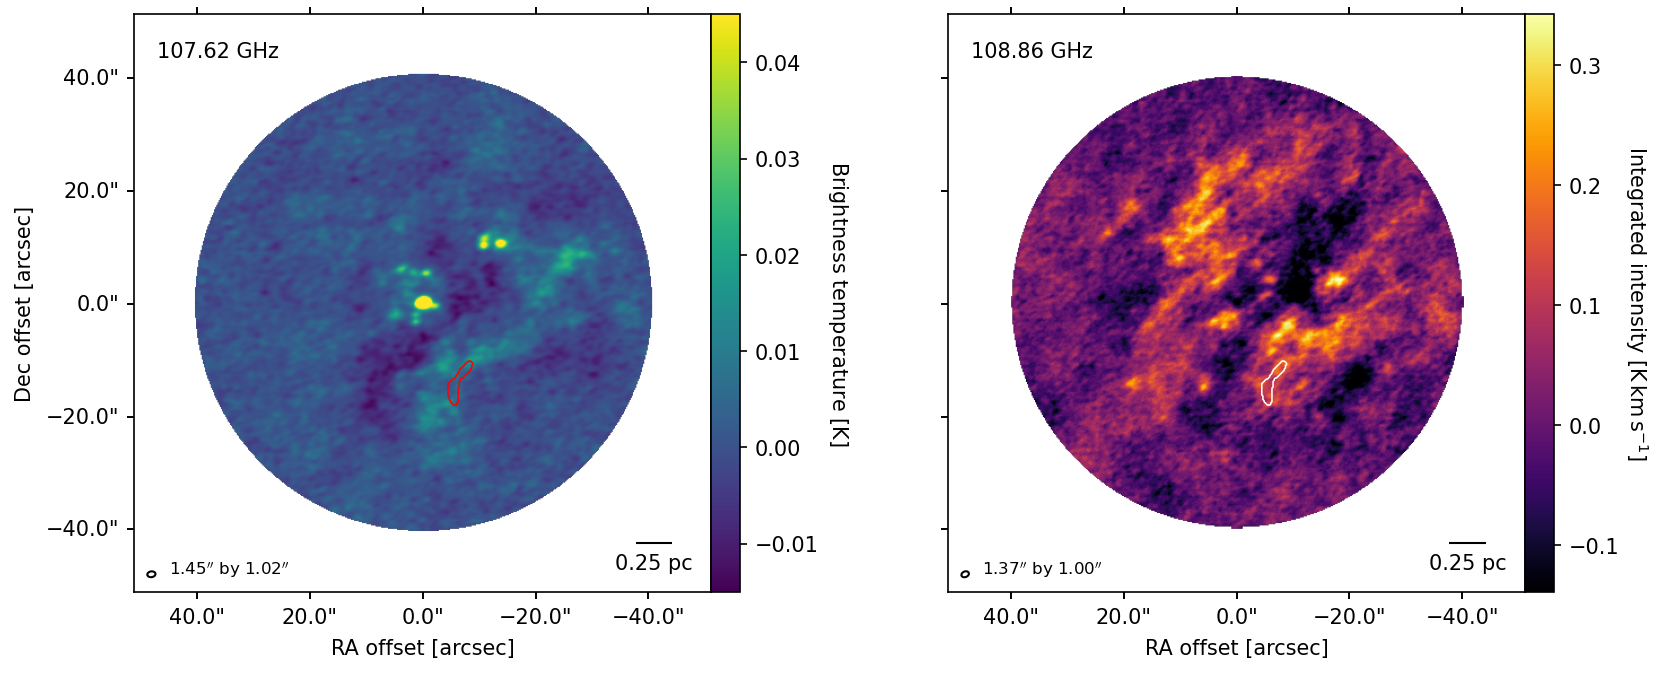

In [66]:
# Set up the figure
fig = plt.figure(figsize=(14,5))
gs = fig.add_gridspec(1, 2, wspace=0)

image_scale = contimage # Set which scale you want to use for both maps
wcs_all = image_scale.wcs.dropaxis(2)

# Create continuum image
ax_cont = fig.add_subplot(gs[0], projection=contimage[0].wcs)
im_cont = ax_cont.imshow(contimage[0].value, origin='lower', cmap='viridis', norm='linear', vmax=0.045, vmin=-0.015)
cbar_cont = plt.colorbar(im_cont, ax=ax_cont, pad=0)

# Create line image
highest_freq_norm = simple_norm(lineimage.value, min_percent = 1, max_percent = 99.99)
lineimage_arr, footprint = reproject_interp((lineimage.value, cube_108_ms.wcs.dropaxis(2)), wcs_all,
                                            shape_out=np.shape(image_scale[0].value))
ax_line = fig.add_subplot(gs[1], projection=wcs_all)    
im_line = ax_line.imshow(lineimage_arr, origin='lower', cmap='inferno', norm = highest_freq_norm)
cbar_line = plt.colorbar(im_line, ax=ax_line, pad=0)

# Label colorbars
cbar_cont.set_label(f"Brightness temperature [{contimage[0].unit.to_string(format = 'latex_inline')}]", rotation=270, labelpad=15)
cbar_line.set_label(f"Integrated intensity [{lineimage[0].unit.to_string(format = 'latex_inline')}]", rotation=270, labelpad=15)

i=0
for ax, cube in zip([ax_cont, ax_line], [contimage, cube_108_ms]):
    # Remove the absolute coordinates
    ra = ax.coords["ra"]
    dec = ax.coords["dec"]
    ra.set_ticks_visible(False)
    ra.set_ticklabel_visible(False)
    dec.set_ticks_visible(False)
    dec.set_ticklabel_visible(False)
    ra.set_axislabel("")
    dec.set_axislabel("")
    # Create an overlay with relative coordinates
    crd = coordinates.SkyCoord("17:46:10.6339473267 -28:42:17.9807702398", frame='icrs', unit=(u.h, u.deg))
    aframe = crd.skyoffset_frame()
    overlay = ax.get_coords_overlay(aframe)
    ra_offset = overlay["lon"]
    dec_offset = overlay["lat"]
    ra_offset.set_axislabel("RA offset [arcsec]")
    dec_offset.set_axislabel("Dec offset [arcsec]")
    ra_offset.set_major_formatter("s.s")
    dec_offset.set_major_formatter("s.s")
    ra_offset.set_ticks_position("bt")
    ra_offset.set_ticklabel_position("b")
    dec_offset.set_ticks_position("lr")
    dec_offset.set_ticklabel_position("l")
    ra_offset.set_axislabel_position("b")
    dec_offset.set_axislabel_position("l")
    if ax == ax_line:
        dec_offset.set_ticklabel_visible(False)
    # Add frown contour
    diffreg = fits.open('diffuse_regions.fits')
    diffreg_mask = diffreg[0].data == 1
    array, footprint = reproject_interp((diffreg_mask, diffreg[0].header), wcs_all.celestial, 
                                        shape_out=np.shape(image_scale[0].value))
    mask = array == 1
    if i == 0:
        ax.contour(mask, levels = [0, 1], linewidths=0.75, colors = ['r'])
    elif i == 1:
        ax.contour(mask, levels = [0, 1], linewidths=0.75, colors = ['w'])
    # Put beam on each image
    pixscale = np.abs((wcs.utils.proj_plane_pixel_area(wcs_all)**0.5*u.deg).to(u.arcsec))
    if i == 0:
        bm = cube.beam
    elif i == 1:
        bm = cube.beams.common_beam(max_iter = 20, max_epsilon = 0.01) # Note: this is the common beam
    bm_str = f"{bm.major.value:.2f}$''$ by {bm.minor.value:.2f}$''$"
    bmell = bm.ellipse_to_plot(15, 15, pixscale)
    bmell.set_facecolor('none')
    bmell.set_edgecolor('k')
    ax.add_artist(bmell)
    plt.text(0.06, 0.03, bm_str, transform=ax.transAxes, size=8)

    # Add center frequency to plot
    freq = str(round(cube.spectral_extrema[0].to(u.GHz).value, 2))+' GHz'
    plt.text(0.04, 0.925, freq, transform=ax.transAxes, size=10)

    # Compute the angle corresponding to 0.25 pc at the distance of the Galactic Center
    gc_distance = 8.0*u.kpc
    scalebar_length = 0.25*u.pc
    scalebar_angle = (scalebar_length / gc_distance).to(u.deg, equivalencies=u.dimensionless_angles())
    # Add a scale bar
    add_scalebar(ax, scalebar_angle, label="0.25 pc", color="black", frame=False)
    
    i+=1

plt.savefig(fig_dir+'/'+f'continuum_vs_line.png', bbox_inches='tight')
plt.savefig(fig_dir+'/'+f'continuum_vs_line.pdf', bbox_inches='tight')
plt.show()